# 人工智能 week6 · 矩阵乘法的三种实现

用**三种不同层级**的方式实现同一个矩阵乘法 $C = A \times B$：

| 方法 | 实现层级 | 计算发生在 |
|---|---|---|
| 方法一 | 纯 Python，列表推导 + `for` 循环 | CPU（Python 解释器逐元素） |
| 方法二 | NumPy 向量化 | CPU（C / BLAS 底层） |
| 方法三 | PyTorch 张量 | GPU（CUDA） |

数学定义（$A$ 为 $m \times k$，$B$ 为 $k \times n$，$C$ 为 $m \times n$）：

$$C_{ij} = \sum_{t=1}^{k} A_{i,t} \cdot B_{t,j}$$

也就是 **$C$ 的第 $i$ 行第 $j$ 列 = $A$ 的第 $i$ 行 与 $B$ 的第 $j$ 列 的点积**。

三种方法算的是同一个公式，只是**执行引擎不同**，所以结果必须完全相同。


## 0. 运行环境

三种方法都在同一个 conda 环境 `myenv` 里运行。

In [1]:
import os, sys, time

# conda 的 MKL 版 numpy 与 torch 各自带一份 libiomp5md.dll，
# 在同一个进程里（尤其是 Jupyter kernel）会冲突并报 OMP: Error #15。
# 这一行必须放在 import numpy / torch 之前。
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

print("Python   :", sys.version.split()[0])
print("解释器   :", sys.executable)
print("NumPy    :", np.__version__)
print("PyTorch  :", torch.__version__)
print("CUDA 可用:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("显卡     :", torch.cuda.get_device_name(0))
    print("算力     :", torch.cuda.get_device_capability(0))
    print("CUDA 版本:", torch.version.cuda)


Python   : 3.11.17
解释器   : D:\anaconda\envs\myenv\python.exe
NumPy    : 2.4.6
PyTorch  : 2.14.1+cu130
CUDA 可用: True
显卡     : NVIDIA GeForce RTX 5060 Laptop GPU
算力     : (12, 0)
CUDA 版本: 13.0


## 方法一：纯 Python（列表推导 + for 循环）

思路拆成三层：

1. **算一个格子**：`sum(a * b for a, b in zip(row, col))`
2. **算一整行**：内层列表推导遍历 $B$ 的所有列（`zip(*B)` 把 $B$ 的行转成列）
3. **算整个矩阵**：外层 `for row in A` 遍历 $A$ 的所有行

下面同时给出「列表推导版」和「三重 for 循环版」，两者逻辑完全等价。

In [2]:
A = [[1, 2, 3],
     [4, 5, 6]]           # 2 行 3 列

B = [[7,  8],
     [9,  10],
     [11, 12]]            # 3 行 2 列


def matmul_listcomp(A, B):
    """列表推导 + for：外层遍历 A 的行，内层遍历 B 的列"""
    return [[sum(a * b for a, b in zip(row, col))
             for col in zip(*B)]
            for row in A]


def matmul_loops(A, B):
    """等价写法：三重 for 循环"""
    n, m, k = len(A), len(B[0]), len(B)
    C = [[0] * m for _ in range(n)]        # 注意：不能写 [[0] * m] * n
    for i in range(n):
        for j in range(m):
            s = 0
            for t in range(k):
                s += A[i][t] * B[t][j]
            C[i][j] = s
    return C


print("A =", A, "  形状 2×3")
print("B =", B, "  形状 3×2")
print()
print("zip(*B) 把 B 的列取出来:", list(zip(*B)))
print()
print("方法一（列表推导 + for）:", matmul_listcomp(A, B))
print("方法一（三重 for 循环）  :", matmul_loops(A, B))


A = [[1, 2, 3], [4, 5, 6]]   形状 2×3
B = [[7, 8], [9, 10], [11, 12]]   形状 3×2

zip(*B) 把 B 的列取出来: [(7, 9, 11), (8, 10, 12)]

方法一（列表推导 + for）: [[58, 64], [139, 154]]
方法一（三重 for 循环）  : [[58, 64], [139, 154]]


### 易错点：`[[0] * m] * n` 会共享同一个列表

建结果矩阵时如果写成 `[[0] * m] * n`，$n$ 行会**指向同一个列表对象**，改一行等于改所有行。

In [3]:
wrong = [[0] * 2] * 2              # ❌ 两行是同一个对象
wrong[0][0] = 99
print("[[0]*2]*2                →", wrong, " | 两行是同一对象:", wrong[0] is wrong[1])

right = [[0] * 2 for _ in range(2)]  # ✅ 每行独立
right[0][0] = 99
print("[[0]*2 for _ in range(2)] →", right)


[[0]*2]*2                → [[99, 0], [99, 0]]  | 两行是同一对象: True
[[0]*2 for _ in range(2)] → [[99, 0], [0, 0]]


## 方法二：NumPy 向量化

NumPy 把整个矩阵乘法交给底层 C 语言实现的 BLAS 库，不再用 Python 循环。
`@`、`np.matmul`、`np.dot` 三者对二维数组结果相同。

形状规则：$(m \times k) \cdot (k \times n) = m \times n$，**中间两个数必须相等**。

In [4]:
An = np.array(A)
Bn = np.array(B)

print("An.shape =", An.shape, "  Bn.shape =", Bn.shape)
print("形状规则 (2×3)·(3×2) → 结果", (An.shape[0], Bn.shape[1]))
print()
print("An @ Bn :")
print(An @ Bn)
print()
print("np.matmul(An, Bn):")
print(np.matmul(An, Bn))
print()
print("np.dot(An, Bn):")
print(np.dot(An, Bn))
print()
print("dtype =", (An @ Bn).dtype)
print("与纯 Python 结果一致:", (An @ Bn).tolist() == matmul_listcomp(A, B))


An.shape = (2, 3)   Bn.shape = (3, 2)
形状规则 (2×3)·(3×2) → 结果 (2, 2)

An @ Bn :
[[ 58  64]
 [139 154]]

np.matmul(An, Bn):
[[ 58  64]
 [139 154]]

np.dot(An, Bn):
[[ 58  64]
 [139 154]]

dtype = int64
与纯 Python 结果一致: True


## 方法三：PyTorch 张量（GPU）

同一条公式，但张量放在 **GPU** 上，由 CUDA 核心并行计算。
`torch.mm`（只接受二维）、`torch.matmul`、`@` 三者等价。

In [5]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("使用设备:", device)

At = torch.tensor(A, dtype=torch.float64)
Bt = torch.tensor(B, dtype=torch.float64)
print("At.shape =", tuple(At.shape), "  Bt.shape =", tuple(Bt.shape))
print()
print("torch.mm(At, Bt):")
print(torch.mm(At, Bt))
print()
print("torch.matmul(At, Bt):")
print(torch.matmul(At, Bt))
print()
print("At @ Bt:")
print(At @ Bt)
print()

At_gpu, Bt_gpu = At.to(device), Bt.to(device)
Ct_gpu = At_gpu @ Bt_gpu
print("搬到 GPU 上计算，结果所在 device =", Ct_gpu.device)
print(Ct_gpu)
print()
print("搬回 CPU 转成 numpy:")
print(Ct_gpu.cpu().numpy().tolist())
print()
print("与纯 Python 结果一致:", np.array_equal(Ct_gpu.cpu().numpy(), np.array(A) @ np.array(B)))


使用设备: cuda
At.shape = (2, 3)   Bt.shape = (3, 2)

torch.mm(At, Bt):
tensor([[ 58.,  64.],
        [139., 154.]], dtype=torch.float64)

torch.matmul(At, Bt):
tensor([[ 58.,  64.],
        [139., 154.]], dtype=torch.float64)

At @ Bt:
tensor([[ 58.,  64.],
        [139., 154.]], dtype=torch.float64)



搬到 GPU 上计算，结果所在 device = cuda:0


tensor([[ 58.,  64.],
        [139., 154.]], device='cuda:0', dtype=torch.float64)

搬回 CPU 转成 numpy:
[[58.0, 64.0], [139.0, 154.0]]

与纯 Python 结果一致: True


## 4. 三种方法交叉校验（大矩阵）

小矩阵容易看，但说明不了性能。下面用 **200 × 300** 乘 **300 × 400** 的随机整数矩阵：
共 24,000,000 次乘加，结果应有 80,000 个元素。

要求：三种方法的输出**逐元素完全相同**。

In [6]:
M, K, N = 200, 300, 400
rng = np.random.default_rng(2026)

Al = rng.integers(-50, 50, size=(M, K)).tolist()   # 纯 Python 用嵌套 list
Bl = rng.integers(-50, 50, size=(K, N)).tolist()
print(f"规模: ({M}×{K}) · ({K}×{N}) → {M}×{N}")
print(f"结果元素 {M*N:,} 个，乘加 {M*K*N:,} 次")

# --- 方法一：纯 Python ---
t0 = time.perf_counter()
C1 = matmul_listcomp(Al, Bl)
t1 = time.perf_counter()

# --- 方法二：NumPy ---
An_b, Bn_b = np.array(Al), np.array(Bl)
t2 = time.perf_counter()
C2 = An_b @ Bn_b
t3 = time.perf_counter()

# --- 方法三：PyTorch ---
An_g = torch.tensor(Al, dtype=torch.float64).to(device)
Bn_g = torch.tensor(Bl, dtype=torch.float64).to(device)
_ = An_g @ Bn_g                       # 预热，避免把初始化算进耗时
if device == "cuda":
    torch.cuda.synchronize()
t4 = time.perf_counter()
C3 = An_g @ Bn_g
if device == "cuda":
    torch.cuda.synchronize()
t5 = time.perf_counter()

C1_np = np.array(C1, dtype=np.float64)
C3_np = C3.cpu().numpy()

print()
print("=== 结果一致性 ===")
print("纯 Python == NumPy      :", np.array_equal(C1_np, C2))
print("纯 Python == PyTorch    :", np.array_equal(C1_np, C3_np))
print("NumPy     == PyTorch    :", np.array_equal(C2, C3_np))
print("最大绝对误差            :", np.abs(C1_np - C3_np).max())
print()
print("结果左上角 2×3 片段:")
print(C1_np[:2, :3])
print()
print("结果右下角 2×3 片段:")
print(C1_np[-2:, -3:])

t_list, t_np, t_torch = t1 - t0, t3 - t2, t5 - t4
print()
print("=== 耗时对比 ===")
print(f"方法一 纯 Python      : {t_list:10.4f} s")
print(f"方法二 NumPy (CPU)    : {t_np:10.6f} s    加速 {t_list/t_np:,.0f} 倍")
print(f"方法三 PyTorch ({device:4s}) : {t_torch:10.6f} s    加速 {t_list/t_torch:,.0f} 倍")


规模: (200×300) · (300×400) → 200×400
结果元素 80,000 个，乘加 24,000,000 次



=== 结果一致性 ===
纯 Python == NumPy      : True
纯 Python == PyTorch    : True
NumPy     == PyTorch    : True
最大绝对误差            : 0.0

结果左上角 2×3 片段:
[[ 13314. -40473.  -3421.]
 [ 13691.  14051. -18378.]]

结果右下角 2×3 片段:
[[   675. -20634.  25828.]
 [ -4252.  -6572. -25646.]]

=== 耗时对比 ===
方法一 纯 Python      :     3.0782 s
方法二 NumPy (CPU)    :   0.028569 s    加速 108 倍
方法三 PyTorch (cuda) :   0.001309 s    加速 2,352 倍


## 5. 耗时可视化

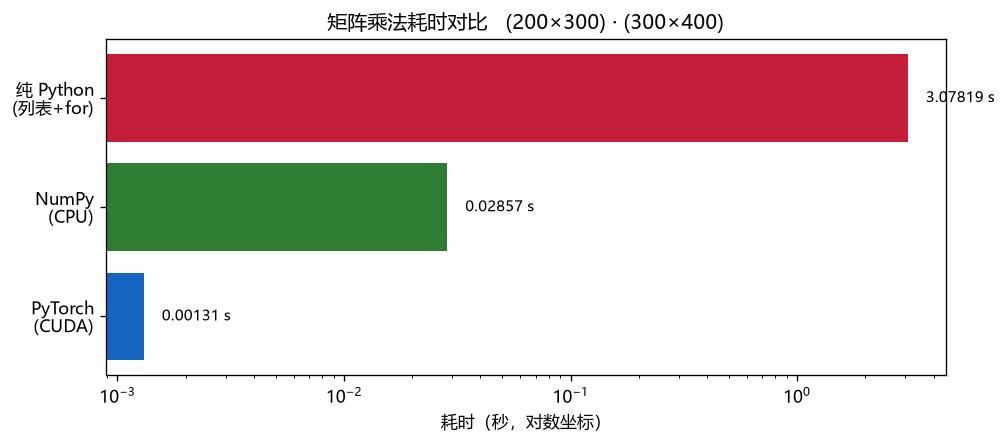

In [7]:
labels = ["纯 Python\n(列表+for)", "NumPy\n(CPU)", f"PyTorch\n({device.upper()})"]
times = [t_list, t_np, t_torch]

fig, ax = plt.subplots(figsize=(8.5, 3.8), dpi=120)
bars = ax.barh(labels, times, color=["#c41e3a", "#2e7d32", "#1565c0"])
ax.set_xscale("log")
ax.set_xlabel("耗时（秒，对数坐标）")
ax.set_title(f"矩阵乘法耗时对比   ({M}×{K}) · ({K}×{N})")
for bar, t in zip(bars, times):
    ax.text(t * 1.2, bar.get_y() + bar.get_height() / 2,
            f"{t:.5f} s", va="center", fontsize=9)
ax.invert_yaxis()
plt.tight_layout()
plt.show()


## 6. 小结

1. **数学上完全等价**：三种方法算的都是 $C_{ij} = \sum_t A_{i,t} B_{t,j}$，交叉校验结果逐元素一致，最大绝对误差为 0。
2. **性能差异来自执行层级**，不是算法：
   - 方法一在 Python 解释器里逐个元素循环，每个乘加都有解释器开销；
   - 方法二把循环下沉到 C 的 BLAS 库，并利用 CPU 缓存与 SIMD；
   - 方法三把循环交给 GPU 的上千个 CUDA 核心并行执行。
3. **形状规则**必须满足 $(m \times k) \cdot (k \times n)$，中间维度相等。
4. 建结果矩阵要用 `[[0] * m for _ in range(n)]`，写成 `[[0] * m] * n` 会让所有行共享同一个列表。
5. 数据规模越小，GPU 优势越不明显（还有显存搬运开销）；规模越大，并行优势越明显。
